In [2]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"





import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import scipy.stats as stats
import sncosmo
from astropy.cosmology import FlatLambdaCDM
from astropy import units as u
from astropy.io import fits
import time
from astropy.table import Table
import warnings
import pickle
import math
from sncosmo.fitting import DataQualityError
from glob import glob
import sys
import multiprocess
multiprocess.set_start_method("fork", force=True)


pd.options.mode.chained_assignment = None
pd.set_option("display.max_columns", None)


OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 FILE_PATH=/media/data1/nikolaos/des_projects/PIP_NS26_DISTRIBUTIONS_TEST_DATADESSIM_IA/ HEADER_OVERRIDE=TRUE NCORES=20 jupyter nbconvert --to notebook --execute shiamrock.ipynb









In [3]:
# GLOBAL PARAMETER
file_path = os.environ.get("FILE_PATH", '/media/data1/nikolaos/des_projects/ed_test/cleaned_snana/')
ncores = int(os.environ.get("NCORES", '5'))
prob = os.environ.get("SNN_PROB_FILE", 'NONE') #/media/data1/nikolaos/des_projects/supernnova/PIPPIN_SNN_PRED_SMP_ENS.h5
HEADER_OVERRIDE = os.environ.get("HEADER_OVERRIDE", 'FALSE')
run_dir =  os.environ.get("SAVE_DIR", file_path)

ZP = float(os.environ.get('ZERO_POINT', '31.4')) #31.4 or 27.5
SNR = int(os.environ.get("SNR", '5')) 
type_z = os.environ.get("TYPE_FIT", 'PHOTOZ')
PHOTFLAG = os.environ.get("PHOTFLAG", 'FALSE')

z_griz_max = float(os.environ.get("GRIZ_MAX", '0.9'))
z_griz_min = float(os.environ.get("GRIZ_MIN", '0.0'))
z_riz_max = float(os.environ.get("RIZ_MAX", '1.2'))
z_riz_min = float(os.environ.get("RIZ_MIN", '0.0'))
dz_width =  float(os.environ.get("BIN_WIDTH", '0.1'))
        
x1_l = float(os.environ.get("X1_LOWER", '-3.5'))
x1_u = float(os.environ.get("X1_UPPER", '3.5'))
c_l = float(os.environ.get("C_LOWER", '-0.2'))
c_u = float(os.environ.get("C_UPPER", '0.5'))
m_d = float(os.environ.get("MAG_DIF", '1.0'))
alpha_cosmo = float(os.environ.get("ALPHA", '0.16'))
beta_cosmo = float(os.environ.get("BETA", '3.0'))
pickle_files = os.environ.get("PICKLE_FILES", 'FALSE') #TRUE / FALSE

save_file = os.path.basename(os.path.normpath(file_path))



print(f"snr: {SNR} ")
print(f"file_path: {file_path} ")

snr: 5 
file_path: /media/data1/nikolaos/des_projects/ed_test/cleaned_snana/ 


In [4]:
# salt_model = 'salt3'
salt_model = sncosmo.SALT3Source(modeldir='SALT3.DOVEKIE/')

In [11]:
def load_snana_directory(path_sim):


    head_files = sorted(glob(os.path.join(path_sim, "*_HEAD.FITS.gz")))
    phot_files = sorted(glob(os.path.join(path_sim, "*_PHOT.FITS.gz")))

    if len(head_files) == 0 or len(phot_files) == 0:
        raise ValueError("No HEAD or PHOT files found.")

    data_h = []
    data_p = []

    # Match HEAD & PHOT files by prefix
    for head_file in head_files:
        prefix = os.path.basename(head_file).replace("_HEAD.FITS.gz", "")

        # # Load HEAD
        # df_head = pd.DataFrame(fits.open(head_file)[1].data)
        # df_head["SNID"] = df_head["SNID"].str.strip()
        # data_h.append(df_head)
    
        t = Table.read(head_file)
        names = [name for name in t.colnames if len(t[name].shape) <= 1]
        df_head = t[names].to_pandas()

        for col in df_head.select_dtypes(include='object'):
            first_valid = df_head[col].dropna().iloc[0] if df_head[col].notna().any() else None
            if isinstance(first_valid, (bytes, bytearray)):
                df_head[col] = df_head[col].str.decode('utf-8').str.strip()
    
        data_h.append(df_head)

        
    for phot_file in phot_files:
        prefix = os.path.basename(phot_file).replace("_PHOT.FITS.gz", "")
       
        # Load PHOT
        data = fits.open(phot_file)[1].data.byteswap().newbyteorder()
        df_phot = pd.DataFrame(data.view(np.recarray))
        if "FLT" in df_phot.columns:
            df_phot.rename(columns={"FLT": "BAND"}, inplace=True)
        df_phot["BAND"] = (
            df_phot["BAND"]
            .str.decode("utf-8")
            .str.strip()
            .str.split("-")
            .str[-1]
        )

        
        data_p.append(table_sncosmo(df_phot))

    return data_h, data_p



def run_id_function(file_id, start, end, data_h=None):

    if file_id == 'NONE':

        if data_h is None or len(data_h) == 0:
            raise ValueError("data_h is empty or not provided.")

        # data_h assumed to be dictionary
        total = pd.concat(data_h, ignore_index=True)
        idd = id_function(total)
        idd = idd[start:end]

    else:

        try:
            ids = pd.read_csv(
                file_id,
                sep=r'\s+',
                compression='gzip',
                comment='#'
            )

        except Exception:
            try:
                ids = pd.read_csv(file_id)

            except Exception:
                try:
                    ids = pd.read_hdf(file_id, key='table')

                except Exception:
                    raise ValueError("Could not read file.")

        idd = id_function(ids)
        idd = idd[start:end]

    return idd


def flagged_photometry(df):
    bad_flags = [8, 16, 32, 64, 128, 256, 512]

    bad_mask = 0
    for flag in bad_flags:
        bad_mask |= flag

    good_rows = (df['PHOTFLAG'] & bad_mask) == 0

    df_clean = df[good_rows]

    # print(f"Removed {len(df) - len(df_clean)} rows with bad flags")
    return df_clean

def estimates_griz_riz(griz, riz):
    griz.rename_column('photoz', 'photoz_griz')
    riz.rename_column('photoz', 'photoz_riz')
    
    # Combine tables column-wise
    t = Table([griz['SNID'], griz['photoz_griz'], riz['photoz_riz']],
              names=('SNID', 'photoz_griz', 'photoz_riz'))
    
    # Create final photoz column
    t['photoz'] = np.where(
        t['photoz_riz'] > 0.9,
        t['photoz_riz'],
        t['photoz_griz']
    )
    
    # Keep only what you need
    final_table = t['SNID', 'photoz']
    return final_table

In [12]:
#function that takes as input the photo data i.e. the data_p1,2,3,4,5 and converts it to the astropy table format. 
#Should run it once for each data_p_ and then only use that sncosmo table.
def table_sncosmo(data_phot):
    # make a astropy table to fit the light curves, we need time, band, flux, flux error, zero point, mag system 
    selected_columns = data_phot[['MJD', 'BAND' , 'FLUXCAL', 'FLUXCALERR', 'PHOTFLAG']]
    # Rename the columns 
    new_column_names = {'MJD': 'mjd', 'BAND': 'band', 'FLUXCAL': 'flux', 'FLUXCALERR': 'fluxerr' } 
    selected_columns.rename(columns=new_column_names, inplace=True)
    # Convert Pandas DataFrame to astropy table
    astropy_table = Table.from_pandas(selected_columns)
    # Replace the bands with the sncosmo band names
    astropy_table['band'] = astropy_table['band'].astype('S4')
    astropy_table['band'][astropy_table['band'] == 'g'] = 'desg'
    astropy_table['band'][astropy_table['band'] == 'r'] = 'desr'
    astropy_table['band'][astropy_table['band'] == 'i'] = 'desi'
    astropy_table['band'][astropy_table['band'] == 'z'] = 'desz'
    astropy_table['band'] = astropy_table['band'].astype(str)
    astropy_table['magsys'] = 'ab'
    astropy_table['zp'] = ZP
    
    return astropy_table


#magnitude function to compute theoretical and observed magnitude for each redshift interval
def mag_comp(z, x0,x1,c, M_trial = -19.35, a=alpha_cosmo, b =beta_cosmo, H_0=70, omega_m=0.3):
    offset = 10.635
    cosmo = FlatLambdaCDM(H0=H_0, Om0= omega_m)
    m_theory = cosmo.distmod(z).value + M_trial
    m_interval = -2.5* np.log10(x0) + a* x1 - b * c + offset
    return  m_theory, m_interval



#quick function that locates the SNIDs of the SN that we are interested in
def id_function(data_p):
    #get the ids of the spectro-z as str
    idd = data_p['SNID'].astype(str)
    idd = idd[ idd != 'nan'] 
    idd = idd.astype(float) ; idd = idd.astype(int) ; idd = idd.astype(str)
    return idd


def truncate_to_sf(x, sig_figs):
    "This is a toy function that I use to check for edge effect systematics. It returns the z of the bin that we need to check"
    if x == 0:
        return 0
    else:
        # Calculate the scaling factor to shift the number to the right
        scale = math.floor(math.log10(abs(x))) + 1
        
        # Truncate by shifting, converting to integer, and then scaling back
        return math.floor(x * 10**(sig_figs - scale)) / 10**(sig_figs - scale)


def check_systematic(z_photo, prec):
    "check for edge degeneracy. Dependin on the precision it changes things. It simply returns a value of 0 or 1 or 2."
    "0 correspnods to ok estimates. 1 corresponds to estimates close to .0000 (lower edge of bin)."
    "2 corresponds to estimates close to .9999 (upper edge of bin)."
    dec_part = np.abs(int(z_photo*10) - z_photo*10)
    dec_part = truncate_to_sf(dec_part, prec)
    limit1 = 10**(-prec)
    check = 0
    if prec ==1 :
        limit2 = 0.9
    elif prec == 2:
        limit2 = 0.99
    elif prec == 3:
        limit2= 0.999
    elif prec == 4:
        limit2= 0.9999    

    if dec_part < 0.5:
        if dec_part < limit1:
            check = 1
    else:
        if dec_part == limit2:
            check=2
    return check
    



In [13]:
def zbins_estimates2(fit_table, SNID, z_min , z_max , dz_width = 0.1, number_of_floating = 2):
    bound = np.round(np.arange(z_min, z_max + dz_width, dz_width), number_of_floating )
    z =[] ; x1=[]; c=[] ; chisqr = []; dof=[] ; x0 = []
    model = sncosmo.Model(source=salt_model)
    if not np.any(fit_table['flux'] / fit_table['fluxerr'] > SNR):
        if not np.any(fit_table['flux'] / fit_table['fluxerr'] > 3):  
            fail = (SNID,
                    np.array([1e8] * (len(bound)-1)),  # chisqr
                    np.array([-999] * (len(bound)-1)), # z
                    np.array([1e8]  * (len(bound)-1)), # x0
                    np.array([-999] * (len(bound)-1)), # x1
                    np.array([-999] * (len(bound)-1)), # c
                    np.array([1e-8] * (len(bound)-1))  # dof
                   )
            return fail
    for i in range(len(bound)-1):   
        try:
            # Use a context manager to catch specific warnings
            with warnings.catch_warnings(record=True) as w:
                warnings.simplefilter("always")  # Catch all warnings
                
                # Attempt to fit the light curve
                r, fm = sncosmo.fit_lc(fit_table, model, ['z', 't0', 'x0', 'x1', 'c'] ,
                                       bounds={'z': (bound[i], bound[i + 1]), 'x1':(-5,5), 'c': (-0.5,0.5),'x0': (0.0,0.1) }, minsnr = SNR)
                # No warnings, so append results
                z.append(r.parameters[0]) ; x0.append(r.parameters[2])
                x1.append(r.parameters[3]) ; c.append(r.parameters[4]) 
                chisqr.append(r.chisq)     ; dof.append(r.ndof)
        except (RuntimeError, DataQualityError): 
            z.append(-999) ; x0.append(1e8)
            x1.append(-999) ; c.append(-999)  
            chisqr.append(1e8) ; dof.append(1e-8)

    chisqr = np.array(chisqr) ; dof = np.array(dof)
    z = np.array(z)   
    x1 = np.array(x1) ; c = np.array(c) 

    return SNID, chisqr, z, x0, x1, c, dof

# function to identify the ids to use 
def lc_fitting_step1_2(data_head, table_for_sncosmo, SNID, bands, z_min , z_max, dz_width):
    id = np.where(data_head['SNID'].str.strip()== SNID)[0]  #SNID must be a string
    if len(id) > 0:
        id=id[0]
        min_phot , max_phot = data_head['PTROBS_MIN'][id], data_head['PTROBS_MAX'][id]
        fit_table = table_for_sncosmo[min_phot-1:max_phot] #maybe it should be min_phot -1
        if PHOTFLAG == 'TRUE':
            fit_table = flagged_photometry(fit_table) #!!!
        fit_table.remove_column('PHOTFLAG') #!!!
        if len(fit_table) > 10:
            ref_mjd = fit_table['mjd'][10]
            fit_table = fit_table[fit_table['mjd'] < (ref_mjd + 200)]
        else:
            # not enough data points, so skip
            return None
        if bands == 'riz':
            fit_table  = fit_table[fit_table['band'] != 'desg']
        
        zbins_es = zbins_estimates2(fit_table, SNID, z_min, z_max, dz_width)
        return  zbins_es
    return  None

#simple loop to run using the lc_fitting_step1
def run_es2(idd, data_h, table_p, bands, z_min , z_max, dz_width):   
    id_yr1 = idd
    zbins_es =[]
    for i in id_yr1:
        zbins_ess = lc_fitting_step1_2(data_h, table_p, i, bands, z_min , z_max, dz_width)
        if zbins_ess is not None:  # Check if the result is valid
            zbins_es.append(zbins_ess)
    return zbins_es


In [14]:

# CHANGE VALUES TO CHANGE PRIORS: x1, c, and Delta_m. 
def loop_for_fitting(zbins_es, x1_l, x1_u, c_l, c_u, m_d, z_max, z_min):
    SNID = zbins_es[0] ; chisqr = zbins_es[1] ; chisqr = np.array(chisqr) 
    z = zbins_es[2]   ; z = np.array(z)  
    x0 = zbins_es[3] ; x0 = np.array(x0)
    x1 =  zbins_es[4] ; x1 = np.array(x1) 
    c =  zbins_es[5] ; c = np.array(c)  
    dof = zbins_es[6] ; dof = np.array(dof)
    r_chisqr = (chisqr/dof)
    min_cond = r_chisqr
    z_initial = z
    while True:
        index = np.argmin(min_cond)
        m_th , m_int = mag_comp(z[index], x0[index],x1[index],c[index], M_trial = -19.35, a=alpha_cosmo, b = beta_cosmo, H_0=70, omega_m=0.3)
        m_th = np.array(m_th) ; m_int = np.array(m_int)
        check = check_systematic(z[index], 3)
        if ((z[index] > z_min + 0.05) and (z[index] < z_max - 0.0001 ) and (x1[index] > x1_l) and (x1[index] < x1_u) and (c[index] > c_l) and (c[index] < c_u)  
            and (np.abs(m_th - m_int) < m_d)):
            if check == 0:
                z_b = z[index] 
                break
            elif check == 1: 
                interval_index = int(z[index] *10) 
                if np.abs(z_initial[interval_index] - z_initial[interval_index-1]) < 0.04:
                    z_b = z[index] 
                    break 
                
            elif check ==2:
                interval_index = int(z[index] *10) 
                if (interval_index+1) < len(z_initial):
                    if np.abs(z_initial[interval_index] - z_initial[interval_index+1]) <0.04:
                        z_b = z[index] 
                        break 
            
        rest_ind = np.where(min_cond > min_cond[index])[0]
        min_cond = min_cond[rest_ind]
        z = z[rest_ind] 
        x0 = x0[rest_ind]
        x1 = x1[rest_ind] 
        c = c[rest_ind] 
        if len(min_cond) < 1:
            z_b = -999 
            break
        
    return SNID, z_b
    

#step 2 simply run the fitting for a single value!
def lc_fitting_step2(zbins_es, x1_l, x1_u, c_l, c_u, m_d, z_max, z_min):
    if zbins_es is not None:
        SNID, z_b, = loop_for_fitting(zbins_es,x1_l, x1_u, c_l, c_u, m_d, z_max, z_min)
        return SNID, z_b

# run loop for all ids that you want
def run_fit(zbins_es, x1_l, x1_u, c_l, c_u, m_d, z_max, z_min): 
    z_t = []  
    id = []
    for i in range(len(zbins_es)):
        ssnid, z_b  = lc_fitting_step2(zbins_es[i],x1_l, x1_u, c_l, c_u, m_d, z_max, z_min)
        if z_b is not None:  # Check if the result is valid
            z_t.append(z_b)
            id.append(ssnid)
    photoz_table = {'SNID': id , 'photoz': z_t}
    table = Table(photoz_table)
    
    return table




In [15]:
# go thourgh each z-bin and calculate the best estimated values, save that so you can access everything anytime and play with cuts
# def chi2_estimate(fit_table, SNID, photo_z, type_z):
#     z =[] ; z_err=[]; t0 =[] ; t0_err =[] ; x0=[] ; x0_err=[]; x1=[]; x1_err=[]; c=[] ; c_err=[] ;  chisqr = []; dof=[]
#     model = sncosmo.Model(source=salt_model)
#     if type_z == 'PHOTOZ':
#         z_ranges = [(0.05, 0.05), (0.03, 0.03), (0.03, 0.02), (0.02, 0.01), (0.01,0.02), (0.01,0.01), (0.002, 0.001), (0.001,0.002), (0.003, 0.001) ,(0.0, 0.0)]
#     for z_add in z_ranges:
#         z_lower, z_upper = photo_z-z_add[0] , photo_z+z_add[1]
#         try:
#             r, f_m = sncosmo.fit_lc(fit_table, model, ['z', 't0', 'x0', 'x1', 'c'] ,
#                                                bounds={'z': (z_lower, z_upper), 'x1':(-5,5), 'c': (-0.5,0.5),'x0': (0.0,0.1) }, minsnr = SNR)
#             break  
#         except Exception:
#             continue
        
#     z.append(r.parameters[0])  ; z_err.append(r.errors['z'])
#     t0.append(r.parameters[1]) ; t0_err.append(r.errors['t0'])
#     x0.append(r.parameters[2]) ; x0_err.append(r.errors['x0'])
#     x1.append(r.parameters[3]) ; x1_err.append(r.errors['x1'])
#     c.append(r.parameters[4])  ; c_err.append(r.errors['c'])
#     chisqr.append(r.chisq)     ; dof.append(r.ndof)
    
#     return SNID, z, z_err, t0, t0_err, x0, x0_err, x1, x1_err, c, c_err, chisqr , dof



def chi2_estimate(fit_table, SNID, photo_z, type_z):
    z =[] ; z_err=[]; t0 =[] ; t0_err =[] ; x0=[] ; x0_err=[]; x1=[]; x1_err=[]; c=[] ; c_err=[] ;  chisqr = []; dof=[]
    model = sncosmo.Model(source=salt_model)
    fit_success = False  
    if type_z == 'PHOTOZ':
        z_ranges = [(0.05, 0.05), (0.03, 0.03), (0.03, 0.02), (0.02, 0.01),(0.01,0.02), (0.01,0.01), (0.002, 0.001), (0.001,0.002), (0.003, 0.001), (0.0, 0.0)]

    for z_add in z_ranges:
        z_lower, z_upper = photo_z - z_add[0], photo_z + z_add[1]
        try:
            r, f_m = sncosmo.fit_lc(fit_table, model,['z', 't0', 'x0', 'x1', 'c'], 
                                    bounds={'z': (z_lower, z_upper), 'x1':(-5,5), 'c': (-0.5,0.5), 'x0': (0.0,0.1)}, minsnr=SNR)
            fit_success = True
            break
        except Exception:
            continue
    if fit_success:
        z.append(r.parameters[0]);   z_err.append(r.errors['z'])
        t0.append(r.parameters[1]); t0_err.append(r.errors['t0'])
        x0.append(r.parameters[2]); x0_err.append(r.errors['x0'])
        x1.append(r.parameters[3]); x1_err.append(r.errors['x1'])
        c.append(r.parameters[4]);  c_err.append(r.errors['c'])
        chisqr.append(r.chisq);     dof.append(r.ndof)
    else:
        # append failure values
        z.append(-999); z_err.append(-999)
        t0.append(-999); t0_err.append(-999)
        x0.append(-999); x0_err.append(-999)
        x1.append(-999); x1_err.append(-999)
        c.append(-999); c_err.append(-999)
        chisqr.append(-999); dof.append(-999)

    return SNID, z, z_err, t0, t0_err, x0, x0_err, x1, x1_err, c, c_err, chisqr, dof


# function to identify the ids to use 
def lc_chi2_step1_2(data_head, table_for_sncosmo, SNID, photo_z, type_z):
    id = np.where(data_head['SNID'].str.strip()== SNID)[0]  #SNID must be a string
    if len(id) > 0:
        id=id[0]
        min_phot , max_phot = data_head['PTROBS_MIN'][id], data_head['PTROBS_MAX'][id]
        fit_table = table_for_sncosmo[min_phot-1:max_phot]
        if PHOTFLAG == 'TRUE':
            fit_table = flagged_photometry(fit_table) #!!!
        fit_table.remove_column('PHOTFLAG') #!!!
        if len(fit_table['mjd']) > 10 :
            fit_table  = fit_table[fit_table['mjd']  < (fit_table['mjd'][10] +200) ]
            zbins_es = chi2_estimate(fit_table, SNID, photo_z, type_z)
        else: 
            zbins_es= None
        return  zbins_es
    return  None

#simple loop to run using the lc_fitting_step1
def run_chi2_es(data, data_h, table_p, type_z = 'PHOTOZ'):   
    id = np.array(id_function(data))
    if type_z == 'PHOTOZ':
        photo_z = np.array(data['photoz'])
    elif type_z == 'SPECZ':
        photo_z = np.array(data['zHEL'])
    zbins_es =[]
    for i in range(len(id)):
        zbins_ess = lc_chi2_step1_2(data_h, table_p, id[i] , photo_z[i], type_z)
        if zbins_ess is not None:  # Check if the result is valid
            zbins_es.append(zbins_ess)
    return zbins_es


def make_table_photoz_pickle(pickle):
    id=[] ; z=[] ; z_err =[] ; t0 =[] ; t0_err =[]
    x0 =[] ; x0_err =[] ; x1 =[] ; x1_err =[]
    c=[] ; c_err =[] ; chisqr = [] ; dof = []
    for i in range(len(pickle)):
        id.append(pickle[i][0])
        z.append(pickle[i][1][0]) ; z_err.append(pickle[i][2][0])
        t0.append(pickle[i][3][0]) ; t0_err.append(pickle[i][4][0])
        x0.append(pickle[i][5][0]) ; x0_err.append(pickle[i][6][0])
        x1.append(pickle[i][7][0]) ; x1_err.append(pickle[i][8][0])
        c.append(pickle[i][9][0]) ; c_err.append(pickle[i][10][0])
        chisqr.append(pickle[i][11][0]) ; dof.append(pickle[i][12][0])
        
    tb = {'SNID': id , 'photoz_sncosmo': z, 'photoz_err_sncosmo': z_err,     
          't0_photoz_sncosmo': t0, 't0_err_photoz_sncosmo': t0_err, 'x0_photoz_sncosmo': x0, 'x0_err_photoz_sncosmo': x0_err, 
          'x1_photoz_sncosmo': x1, 'x1_err_photoz_sncosmo': x1_err, 'c_photoz_sncosmo': c, 'c_err_photoz_sncosmo': c_err, 
         'chisqr_sncosmo' : chisqr  , 'dof_sncosmo': dof }
    table = Table(tb)
    return table




    

In [16]:
data_h, table_p = load_snana_directory(file_path)
total = pd.concat(data_h, ignore_index=True)

KeyError: 'BAND'

In [21]:
start = int(os.environ.get("START", '0'))
end = int(os.environ.get("END", len(total)))

In [22]:
idd = run_id_function(prob, start, end , data_h=data_h)

In [23]:
def run_shiamrock(proc_id, data_h, table_p, idd, z_griz_min, z_griz_max, z_riz_min, z_riz_max, dz_width):
    print(f'Process {proc_id} running with IDs: {idd}...')
    
    griz = []
    for dh, tp in zip(data_h, table_p):
        griz += run_es2(idd, dh, tp,
                        bands='griz',
                        z_min= z_griz_min,
                        z_max= z_griz_max, dz_width = dz_width)
    
    #pickle dump here
    filename_griz = os.path.join(run_dir, f"photoz_estimates_snr_{SNR}_griz_{start}_{end}_{proc_id}.pkl")
    
    with open(filename_griz, 'wb') as f:
        pickle.dump(griz, f)
    
    
    riz = []
    for dh, tp in zip(data_h, table_p):
        riz += run_es2(idd, dh, tp,
                        bands='riz',
                        z_min= z_riz_min,
                        z_max= z_riz_max  , dz_width = dz_width)  
    
    
    
    #pickle dump here
    filename_riz = os.path.join(run_dir, f"photoz_estimates_snr_{SNR}_riz_{start}_{end}_{proc_id}.pkl")
    
    with open(filename_riz, 'wb') as f:
        pickle.dump(riz, f)
    
    
    z_griz = run_fit(griz, x1_l, x1_u, c_l, c_u, m_d, z_griz_max, z_griz_min)
    
    z_riz = run_fit(riz, x1_l, x1_u, c_l, c_u, m_d, z_riz_max, z_riz_min)
    
    dd = estimates_griz_riz(z_griz, z_riz)
    
    
    
    dd = dd[dd['photoz'] >0 ]
    est = []
    for dh, tp in zip(data_h, table_p):
        est += run_chi2_es(dd, dh, tp, type_z)

    df = make_table_photoz_pickle(est).to_pandas()
    #save it here too.
    filename_df = os.path.join(run_dir, f"shiamrock_trial_{proc_id}.csv")
    df.to_csv(filename_df, sep = ' ', index = False )

    return 




def split_paths(a, n):
    """
    Splits images evenly among requested processes
    """

    k, m = divmod(len(a), n)

    return (a[i * k +  min(i, m) : (i + 1) * k + min(i + 1, m)] for i in range(n))

In [24]:

# if __name__ == "__main__":
#     start_clock = time.perf_counter()
#     split_ids = list(split_paths(list(idd), ncores))
#     jobs, proc_ids = [], []
#     for proc_id in range(ncores):
#         if split_ids[proc_id]:
#             proc = multiprocess.Process(target=run_shiamrock, 
#                                         args=(proc_id, data_h, table_p, split_ids[proc_id], z_griz_min, z_griz_max, z_riz_min, z_riz_max, dz_width))
#             jobs.append(proc)
#             proc_ids.append(proc_id)

#     for j in jobs:
#         j.start()
#     for j in jobs:
#         j.join()

#     all_griz = []
#     all_riz = []
#     all_dfs = []
    
#     for proc_id in proc_ids:

        
#         filename_griz = os.path.join(run_dir,f"photoz_estimates_snr_{SNR}_griz_{start}_{end}_{proc_id}.pkl")
#         with open(filename_griz, "rb") as f:
#             all_griz += pickle.load(f)
    
#         filename_riz = os.path.join(run_dir,f"photoz_estimates_snr_{SNR}_riz_{start}_{end}_{proc_id}.pkl")
#         with open(filename_riz, "rb") as f:
#             all_riz += pickle.load(f)
    
#         filename_df = os.path.join(run_dir, f"shiamrock_trial_{proc_id}.csv")
#         df_part = pd.read_csv(filename_df,
#                               sep=" ")
#         all_dfs.append(df_part)
    
#     df_all = pd.concat(all_dfs, ignore_index=True)
#     df_all = df_all[df_all['photoz_sncosmo'] > 0]
    
#     filename_griz_all = os.path.join(run_dir,f"{save_file}_photoz_estimates_snr_{SNR}_griz_{start}_{end}_ALL.pkl")
#     with open(filename_griz_all, "wb") as f:
#         pickle.dump(all_griz, f)

#     filename_riz_all = os.path.join(run_dir,f"{save_file}_photoz_estimates_snr_{SNR}_riz_{start}_{end}_ALL.pkl")
#     with open(filename_riz_all, "wb") as f:
#         pickle.dump(all_riz, f)

#     filename_df_all = os.path.join(run_dir,f"{save_file}_shiamrock_{start}_{end}_ALL.csv")
#     df_all.to_csv(filename_df_all, sep=" ", index=False)
    
    
#     for proc_id in proc_ids:
    
#         os.remove(os.path.join(run_dir,f"photoz_estimates_snr_{SNR}_griz_{start}_{end}_{proc_id}.pkl"))
#         os.remove(os.path.join(run_dir,f"photoz_estimates_snr_{SNR}_riz_{start}_{end}_{proc_id}.pkl"))
#         os.remove(os.path.join(run_dir,f"shiamrock_trial_{proc_id}.csv"))

    
# #     end_clock = time.perf_counter()
#     print('TOTAL TIME THAT WE CARE: ', end_clock - start_clock, 'seconds OR', (end_clock - start_clock)/60, 'min' )
            

In [25]:
if __name__ == "__main__":
    start_clock = time.perf_counter()
    if pickle_files == 'FALSE': 
        split_ids = list(split_paths(list(idd), ncores))
        jobs, proc_ids = [], []
        for proc_id in range(ncores):
            if split_ids[proc_id]:
                proc = multiprocess.Process(target=run_shiamrock, 
                                            args=(proc_id, data_h, table_p, split_ids[proc_id], z_griz_min, z_griz_max, z_riz_min, z_riz_max, dz_width))
                jobs.append(proc)
                proc_ids.append(proc_id)
    
        for j in jobs:
            j.start()
        for j in jobs:
            j.join()
    
        all_griz = []
        all_riz = []
        all_dfs = []
        
        for proc_id in proc_ids:
    
            
            filename_griz = os.path.join(run_dir,f"photoz_estimates_snr_{SNR}_griz_{start}_{end}_{proc_id}.pkl")
            with open(filename_griz, "rb") as f:
                all_griz += pickle.load(f)
        
            filename_riz = os.path.join(run_dir,f"photoz_estimates_snr_{SNR}_riz_{start}_{end}_{proc_id}.pkl")
            with open(filename_riz, "rb") as f:
                all_riz += pickle.load(f)
        
            filename_df = os.path.join(run_dir, f"shiamrock_trial_{proc_id}.csv")
            df_part = pd.read_csv(filename_df,
                                  sep=" ")
            all_dfs.append(df_part)
        
        df_all = pd.concat(all_dfs, ignore_index=True)
        df_all = df_all[df_all['photoz_sncosmo'] > 0]
        
        filename_griz_all = os.path.join(run_dir,f"{save_file}_photoz_estimates_snr_{SNR}_griz_{start}_{end}_ALL.pkl")
        with open(filename_griz_all, "wb") as f:
            pickle.dump(all_griz, f)
    
        filename_riz_all = os.path.join(run_dir,f"{save_file}_photoz_estimates_snr_{SNR}_riz_{start}_{end}_ALL.pkl")
        with open(filename_riz_all, "wb") as f:
            pickle.dump(all_riz, f)
    
        filename_df_all = os.path.join(run_dir,f"{save_file}_shiamrock_{start}_{end}_ALL.csv")
        df_all.to_csv(filename_df_all, sep=" ", index=False)
        
        
        for proc_id in proc_ids:
        
            os.remove(os.path.join(run_dir,f"photoz_estimates_snr_{SNR}_griz_{start}_{end}_{proc_id}.pkl"))
            os.remove(os.path.join(run_dir,f"photoz_estimates_snr_{SNR}_riz_{start}_{end}_{proc_id}.pkl"))
            os.remove(os.path.join(run_dir,f"shiamrock_trial_{proc_id}.csv"))

    elif pickle_files == "TRUE":
        
        
        filename_griz = os.path.join(run_dir,f"{save_file}_photoz_estimates_snr_{SNR}_griz_{start}_{end}_ALL.pkl")
        filename_riz = os.path.join(run_dir,f"{save_file}_photoz_estimates_snr_{SNR}_riz_{start}_{end}_ALL.pkl")


        with open(filename_griz, "rb") as f:
            griz = pickle.load(f)
            
        with open(filename_riz, "rb") as f:
            riz = pickle.load(f)

        z_griz = run_fit(griz, x1_l, x1_u, c_l, c_u, m_d, z_griz_max, z_griz_min)
        z_riz = run_fit(riz, x1_l, x1_u, c_l, c_u, m_d, z_riz_max, z_riz_min)
    
        dd = estimates_griz_riz(z_griz, z_riz)
    
    
    
        dd = dd[dd['photoz'] >0 ]
        est = []
        
        for dh, tp in zip(data_h, table_p):
            est += run_chi2_es(dd, dh, tp, type_z)

        df = make_table_photoz_pickle(est).to_pandas()
        #save it here too.
        filename_df = os.path.join(run_dir, f"shiamrock_a_{alpha_cosmo}_b_{beta_cosmo}_Dm_{m_d}_{x1_l}_x1_{x1_u}_{c_l}_c_{c_u}_trial.csv")
        df.to_csv(filename_df, sep = ' ', index = False )


    
    end_clock = time.perf_counter()
    print('TOTAL TIME THAT WE CARE: ', end_clock - start_clock, 'seconds OR', (end_clock - start_clock)/60, 'min' )
            

Process 0 running with IDs: ['80545', '462550']...
Process 1 running with IDs: ['78202', '666198']...

Process 2 running with IDs: ['5874', '447767']...Process 3 running with IDs: ['597533', '242269']...
Process 4 running with IDs: ['8487', '626697']...


/media/data1/nikolaos/anaconda/lib/python3.12/site-packages/astropy/cosmology/flrw/lambdacdm.py:397: RuntimeWarning: invalid value encountered in sqrt
  return 2 * np.sqrt(x) * hyp2f1(1.0 / 6, 1.0 / 2, 7.0 / 6, -(x**3))
/media/data1/nikolaos/anaconda/lib/python3.12/site-packages/astropy/cosmology/flrw/lambdacdm.py:397: RuntimeWarning: invalid value encountered in sqrt
  return 2 * np.sqrt(x) * hyp2f1(1.0 / 6, 1.0 / 2, 7.0 / 6, -(x**3))
/media/data1/nikolaos/anaconda/lib/python3.12/site-packages/astropy/cosmology/flrw/lambdacdm.py:397: RuntimeWarning: invalid value encountered in sqrt
  return 2 * np.sqrt(x) * hyp2f1(1.0 / 6, 1.0 / 2, 7.0 / 6, -(x**3))
/media/data1/nikolaos/anaconda/lib/python3.12/site-packages/astropy/cosmology/flrw/lambdacdm.py:397: RuntimeWarning: invalid value encountered in sqrt
  return 2 * np.sqrt(x) * hyp2f1(1.0 / 6, 1.0 / 2, 7.0 / 6, -(x**3))
/media/data1/nikolaos/anaconda/lib/python3.12/site-packages/astropy/cosmology/flrw/lambdacdm.py:397: RuntimeWarning: inv

TOTAL TIME THAT WE CARE:  22.841908410191536 seconds OR 0.38069847350319225 min


/tmp/ipykernel_2891800/2286810789.py:38: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_all = pd.concat(all_dfs, ignore_index=True)


In [44]:
#add the HEADER OVERRIDE FILE here


df = pd.read_csv(os.path.join(run_dir,f"{save_file}_shiamrock_{start}_{end}_ALL.csv"), sep = ' ')
df = df[df['photoz_sncosmo'] > 0.05]

total = pd.concat(data_h, ignore_index=True)
total['SNID'] = total['SNID'].astype(int)
n = pd.merge(total, df, on = 'SNID', how = 'left')

n['SNID'] = n['SNID'].astype(int)
n.rename(columns = {'SNID' : 'CID'}, inplace = True)
n = n[['CID', 'photoz_sncosmo', 'photoz_err_sncosmo']]
n['photoz_sncosmo'] = n['photoz_sncosmo'].fillna(-999.00)
n['photoz_err_sncosmo'] = n['photoz_err_sncosmo'].fillna(-999.00)



new = total[['SNID', 'REDSHIFT_HELIO', 'HOSTGAL_SPECZ', 'REDSHIFT_FINAL', 'REDSHIFT_HELIO_ERR', 'HOSTGAL_SPECZ_ERR','REDSHIFT_FINAL_ERR' ]]
new['VARNAMES:'] = 'SN:'
new = new[['VARNAMES:'] + list(new.columns.drop('VARNAMES:'))]


new['REDSHIFT_HELIO'] = n['photoz_sncosmo']
new['REDSHIFT_HELIO_ERR'] = n['photoz_err_sncosmo']
new['REDSHIFT_FINAL'] = n['photoz_sncosmo']
new['REDSHIFT_FINAL_ERR'] =n['photoz_err_sncosmo']
new['HOSTGAL_SPECZ'] = n['photoz_sncosmo']
new['HOSTGAL_SPECZ_ERR'] = n['photoz_err_sncosmo']
# new['SIM_REDSHIFT_HOST_MATCH'] = n['photoz_sncosmo']
# new['SIM_REDSHIFT_HELIO'] = n['photoz_sncosmo']
# new['SIM_REDSHIFT_CMB'] = n['photoz_sncosmo']
# new['SIM_REDSHIFT_HOST'] = n['photoz_sncosmo']

		


if HEADER_OVERRIDE == 'TRUE':
    new.to_csv(os.path.join(run_dir,f"{save_file}_shiamrock_HEADER_OVERRIDE.dat"), sep = ' ' , index = False )
    


In [58]:



# with open('/media/data1/nikolaos/des_projects/PIP_NS26_BBC_SIMS_SIMS_BBC/photoz_estimates_snr_5_griz_0_387305_4.pkl', "rb") as f:
#     all_griz = pickle.load(f)


# with open( '/media/data1/nikolaos/des_projects/PIP_NS26_BBC_SIMS_SIMS_BBC/photoz_estimates_snr_5_riz_0_387305_4.pkl', "rb") as f:
#     all_riz = pickle.load(f)


# print('now the griz')
# z_griz = run_fit(all_griz, x1_l, x1_u, c_l, c_u, m_d, z_griz_max, z_griz_min)


# print('now the riz')
# z_riz = run_fit(all_riz, x1_l, x1_u, c_l, c_u, m_d, z_riz_max, z_riz_min)


# print('now select')
# dd = estimates_griz_riz(z_griz, z_riz)



# dd = dd[dd['photoz'] >0 ]
# est = []
# for dh, tp in zip(data_h, table_p):
#     est += run_chi2_es(dd, dh, tp, type_z)



# df = make_table_photoz_pickle(est).to_pandas()
# #save it here too.
# df.to_csv('/media/data1/nikolaos/des_projects/PIP_NS26_BBC_SIMS_SIMS_BBC/z_shiamrock_trial_for_failed_4.csv', sep = ' ', index = False )


In [28]:
from scipy.stats import gaussian_kde
def photometric_values(df):
    count =0 
    for i in range(len(df)):
        if np.abs(np.array(df['REDSHIFT_FINAL'])[i] - np.array(df['photoz_sncosmo'])[i]) > 0.15 * (1+np.array(df['REDSHIFT_FINAL'])[i]):
            count = count +1
    print(count, 'catastrophic outliers')
    print('catastrophic outliers percentage: ', count/ len(df) * 100, '%')
    print()
    
    bias = np.median((np.array(df['REDSHIFT_FINAL'])) - np.array(df['photoz_sncosmo']) )
    print('bias: ', bias)
    print()

    sigma_nmad = 1.48 * np.median(np.abs((np.array(df['REDSHIFT_FINAL'])) - np.array(df['photoz_sncosmo']))/ (1 +np.array(df['REDSHIFT_FINAL'])))
    print('simga_nmad: ', sigma_nmad)

    print('Dz_norm std: ', np.std(   (np.array(df['REDSHIFT_FINAL'])) - np.array(df['photoz_sncosmo']) / (1 +np.array(df['REDSHIFT_FINAL']))) )
    
    return 


def plot_photoz_density_mnras(specz, photoz, photoz_err, title, lb, x_size, y_size):
    # Plot settings

    cmap = 'inferno'
    point_size = 10

    specz = np.asarray(specz)
    photoz = np.asarray(photoz)
    photoz_err = np.asarray(photoz_err)

    lab = str(len(photoz))

    xy = np.vstack([specz, photoz])
    kde = gaussian_kde(xy)
    z = kde(xy)
    alpha_values = np.interp(z, (1, np.max(z)), (0.5, 1))
    idx = z.argsort()

    specz, photoz, z, photoz_err, alpha_values = specz[idx], photoz[idx], z[idx], photoz_err[idx], alpha_values[idx]

    fig, ax = plt.subplots(figsize=(x_size, y_size), dpi=600)
    x_line = np.linspace(0, 1.3, 100)
    delta_z = 0.15 * (1 + x_line)
    ax.plot(x_line, x_line + delta_z, color='green', linestyle='--', linewidth=1.5, label=r'$ (z_\text{photo}-z_\text{spec}) / (1 + z_\text{spec}) = \pm 0.15$' + ' (catastrophic boundaries)')
    ax.plot(x_line, x_line - delta_z, color='green', linestyle='--', linewidth=1.5)

    ax.plot([0, 1.3], [0, 1.3], ls='--', linewidth=1.2, color='black', label='Ideal Match (1:1)')
    
    norm = plt.Normalize(vmin=z.min(), vmax=z.max())
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)

    for i in range(len(specz)):
        ax.errorbar(specz[i], photoz[i], yerr=photoz_err[i],
                    fmt='none', 
                    ecolor=sm.to_rgba(z[i]), 
                    alpha=0.3, 
                    elinewidth=0.2, 
                    capthick=0.2, 
                    capsize=0.2)

    sc = ax.scatter(specz, photoz, c=z, s=point_size, cmap=cmap,
                    alpha=alpha_values, edgecolors='none', label=lab + lb)


    ax.set_xlabel(r"Simulated Host Spectroscopic Redshift " + r'$(z_{\text{spec}})$')
    ax.set_ylabel(r"SN Photometric Redshift " + r'$(z_{\text{photo}})$')

    ax.set_title(title)
    ax.legend(loc='upper left', frameon=True, framealpha=0.5, handletextpad=0.3, borderpad=0.3)
    xticks = np.arange(0, 1.4, 0.1)
    yticks = np.arange(0, 1.4, 0.1)
    
    # Remove the 0.0 label from x and y ticks
    xtick_labels = ["" if val == 0 else f"{val:.1f}" for val in xticks]
    ytick_labels = ["" if val == 0 else f"{val:.1f}" for val in yticks]
    
    ax.set_xticks(xticks)
    ax.set_xticklabels(xtick_labels)
    ax.set_yticks(yticks)
    ax.set_yticklabels(ytick_labels)
    ax.text(0, 0, "0.0", ha='right', va='top', fontsize=25)

    ax.set_xlim(0, 1.2)
    ax.set_ylim(0, 1.2)
   
    fig.tight_layout()
    return


# Plot settings
plt.rcParams.update({
        'font.family': 'serif',
        'font.size': 15,
        'axes.labelsize': 20, #20 or 18
        'axes.titlesize': 18,
        'xtick.labelsize': 16, #16 or 14
        'ytick.labelsize': 16, #16 or 14
        'legend.fontsize': 10,
        'axes.titlepad': 12,
        'axes.labelpad': 12,
        'xtick.direction': 'in',
        'ytick.direction': 'in',
        'xtick.top': True,
        'ytick.right': True,
        'xtick.minor.visible': True,
        'ytick.minor.visible': True,
        'axes.linewidth': 1.2,})

In [15]:
# df_taylor = pd.read_csv('/media/data1/nikolaos/des_projects/PIP_NS26_DISTRIBUTIONS_TEST_DATADESSIM_IA/z_PIP_NS26_DISTRIBUTIONS_TEST_DATADESSIM_IA_shiamrock_0_15265_ALL.csv', sep = ' ')
# df_dov = pd.read_csv('/media/data1/nikolaos/des_projects/PIP_NS26_DISTRIBUTIONS_TEST_DATADESSIM_IA/z_SALT3DOV_PIP_NS26_DISTRIBUTIONS_TEST_DATADESSIM_IA_shiamrock_0_15265_ALL.csv', sep = ' ')
# df_taylor = df_taylor[['SNID', 'photoz_sncosmo', 'photoz_err_sncosmo']]
# df_taylor
# df_dov = df_dov[['SNID', 'photoz_sncosmo', 'photoz_err_sncosmo']]
# df_dov
# total['SNID'] = total['SNID'].astype(int)

In [37]:
# snana_taylor = pd.read_csv('FITOPT000_DISTRIBUTIONS_TEST.FITRES.gz',  sep=r'\s+', compression='gzip', comment='#')
# snana_dov = pd.read_csv('FITOPT000_DISTRIBUTIONS_TEST_DOV.FITRES.gz',  sep=r'\s+', compression='gzip', comment='#')


# snana_taylor = snana_taylor[snana_taylor['PROB_model1'] > 0.5]
# snana_taylor = snana_taylor[ ((np.abs(snana_taylor['x1']) < 3) & (np.abs(snana_taylor['c']) < 0.3) & 
#             (snana_taylor['x1ERR'] < 1.15)  & (snana_taylor['PKMJDERR'] < 2)  &  (snana_taylor['cERR'] < 0.2)   & 
#                   (snana_taylor['FITPROB'] > 0.001) )]


# snana_dov = snana_dov[snana_dov['PROB_model1'] > 0.5]
# snana_dov = snana_dov[ ((np.abs(snana_dov['x1']) < 3) & (np.abs(snana_dov['c']) < 0.3) & 
#             (snana_dov['x1ERR'] < 1.15)  & (snana_dov['PKMJDERR'] < 2)  &  (snana_dov['cERR'] < 0.2)   & 
#                   (snana_dov['FITPROB'] > 0.001) )]

In [45]:
# trial_taylor = pd.merge(total, df_taylor, how = 'left', on = 'SNID')
# trial_taylor = trial_taylor[trial_taylor['photoz_sncosmo'] >0]
# trial_taylor = pd.merge(snana_taylor, trial_taylor, how = 'left', left_on = 'CID', right_on = 'SNID') 
# trial_taylor 

,VARNAMES:,CID,CIDint,IDSURVEY,TYPE,FIELD,CUTFLAG_SNANA,ERRFLAG_FIT,RA_x,DEC_x,zHEL,zHELERR,zCMB,zCMBERR,zHD,zHDERR,VPEC_x,VPECERR,LENSDMU_x,LENSDMUERR,MWEBV_x,HOST_NMATCH,HOST_NMATCH2,HOST_OBJID,HOST_ZPHOT,HOST_ZPHOTERR,HOST_ZSPEC,HOST_ZSPECERR,HOST_RA,HOST_DEC,HOST_ANGSEP,HOST_DDLR,HOST_CONFUSION,HOST_LOGMASS,HOST_LOGMASS_ERR,HOST_LOGSFR,HOST_LOGSFR_ERR,HOST_LOGsSFR,HOST_LOGsSFR_ERR,HOST_COLOR,HOST_COLOR_ERR,HOST_MAG_g,HOST_MAG_r,HOST_MAG_i,HOST_MAG_z,HOST_MAGERR_g,HOST_MAGERR_r,HOST_MAGERR_i,HOST_MAGERR_z,HOST_SBFLUXCAL_g,HOST_SBFLUXCAL_r,HOST_SBFLUXCAL_i,HOST_SBFLUXCAL_z,HOST_SBMAG_g,HOST_SBMAG_r,HOST_SBMAG_i,HOST_SBMAG_z,PKMJDINI,SNRMAX1,SNRMAX2,SNRMAX3,SNRSUM,BANDLIST,PKMJD,PKMJDERR,x1,x1ERR,c,cERR,mB,mBERR,x0,x0ERR,COV_x1_c,COV_x1_x0,COV_c_x0,NDOF,FITCHI2,FITPROB,RADIUS_POP,SIM_GENTYPE_x,SIM_TEMPLATE_INDEX_x,SIM_LIBID_x,SIM_NGEN_LIBID_x,SIM_ZCMB,SIM_ZHOST_MATCH,SIM_ZFLAG,SIM_VPEC_x,SIM_DLMAG,SIM_LENSDMU_x,SIM_PEAKMJD_x,SIM_WGT_POP,SIM_x1,SIM_c,SIM_alpha,SIM_beta,SIM_gammaDM,SIM_x0,SIM_mB,SIM_AV_x,SIM_RV_x,SIM_HOSTLIB_GALID_x,SIM_HOSTLIB_r_obs_auto,SIM_HOSTLIB_obs_gr_auto,SIM_HOSTLIB_LOGMASS_TRUE,SIM_HOSTLIB_ZTRUE,RA_2,DEC_2,HOST_ANGSEP_2,TGAPMAX,TrestMIN,TrestMAX,FLUXCALMAX_g,SNRMAX_g,FLUXCALMAX_r,SNRMAX_r,FLUXCALMAX_i,SNRMAX_i,FLUXCALMAX_z,SNRMAX_z,m0obs_r,m0obs_i,m0obs_g,PROB_model1,SNID,FAKE,RA_y,DEC_y,PIXSIZE,NXPIX,NYPIX,SNTYPE,NOBS,PTROBS_MIN,PTROBS_MAX,MWEBV_y,MWEBV_ERR,REDSHIFT_HELIO,REDSHIFT_HELIO_ERR,REDSHIFT_FINAL,REDSHIFT_FINAL_ERR,MASK_REDSHIFT_SOURCE,VPEC_y,VPEC_ERR,LENSDMU_y,LENSDMU_ERR,HOSTGAL_NMATCH,HOSTGAL_NMATCH2,HOSTGAL_OBJID,HOSTGAL_FLAG,HOSTGAL_PHOTOZ,HOSTGAL_PHOTOZ_ERR,HOSTGAL_SPECZ,HOSTGAL_SPECZ_ERR,HOSTGAL_RA,HOSTGAL_DEC,HOSTGAL_SNSEP,HOSTGAL_DDLR,HOSTGAL_CONFUSION,HOSTGAL_LOGMASS,HOSTGAL_LOGMASS_ERR,HOSTGAL_LOGSFR,HOSTGAL_LOGSFR_ERR,HOSTGAL_LOGsSFR,HOSTGAL_LOGsSFR_ERR,HOSTGAL_COLOR,HOSTGAL_COLOR_ERR,HOSTGAL_ELLIPTICITY,HOSTGAL_OBJID2,HOSTGAL_SQRADIUS,HOSTGAL_OBJID_UNIQUE,HOSTGAL_MAG_g,HOSTGAL_MAG_r,HOSTGAL_MAG_i,HOSTGAL_MAG_z,HOSTGAL_MAGERR_g,HOSTGAL_MAGERR_r,HOSTGAL_MAGERR_i,HOSTGAL_MAGERR_z,HOSTGAL2_OBJID,HOSTGAL2_FLAG,HOSTGAL2_PHOTOZ,HOSTGAL2_PHOTOZ_ERR,HOSTGAL2_SPECZ,HOSTGAL2_SPECZ_ERR,HOSTGAL2_RA,HOSTGAL2_DEC,HOSTGAL2_SNSEP,HOSTGAL2_DDLR,HOSTGAL2_LOGMASS,HOSTGAL2_LOGMASS_ERR,HOSTGAL2_LOGSFR,HOSTGAL2_LOGSFR_ERR,HOSTGAL2_LOGsSFR,HOSTGAL2_LOGsSFR_ERR,HOSTGAL2_COLOR,HOSTGAL2_COLOR_ERR,HOSTGAL2_ELLIPTICITY,HOSTGAL2_OBJID2,HOSTGAL2_SQRADIUS,HOSTGAL2_OBJID_UNIQUE,HOSTGAL2_MAG_g,HOSTGAL2_MAG_r,HOSTGAL2_MAG_i,HOSTGAL2_MAG_z,HOSTGAL2_MAGERR_g,HOSTGAL2_MAGERR_r,HOSTGAL2_MAGERR_i,HOSTGAL2_MAGERR_z,HOSTGAL_SB_FLUXCAL_g,HOSTGAL_SB_FLUXCAL_r,HOSTGAL_SB_FLUXCAL_i,HOSTGAL_SB_FLUXCAL_z,PEAKMJD,MJD_TRIGGER,MJD_DETECT_FIRST,MJD_DETECT_LAST,SEARCH_TYPE,SIM_MODEL_NAME,SIM_MODEL_INDEX,SIM_GENTYPE_y,SIM_TYPE_INDEX,SIM_TYPE_NAME,SIM_TEMPLATE_INDEX_y,SIM_LIBID_y,SIM_NGEN_LIBID_y,SIM_NOBS_UNDEFINED,SIM_SEARCHEFF_MASK,SIM_REDSHIFT_HELIO,SIM_REDSHIFT_CMB,SIM_REDSHIFT_HOST,SIM_REDSHIFT_HOST_MATCH,SIM_REDSHIFT_FLAG,SIM_VPEC_y,SIM_HOSTLIB_GALID_y,SIM_HOSTLIB(r_obs_auto),SIM_HOSTLIB(obs_gr_auto),SIM_HOSTLIB(LOGMASS_TRUE),SIM_HOSTLIB(ZTRUE),SIM_SNHOST_DDLR,SIM_SNHOST_SEP,SIM_DLMU,SIM_LENSDMU_y,SIM_MUSHIFT,SIM_RA,SIM_DEC,SIM_MWEBV,SIM_PEAKMJD_y,SIM_MJD_EXPLODE,SIM_MAGSMEAR_COH,SIM_WGT_POPULATION,SIM_AV_y,SIM_RV_y,SIM_SALT2x0,SIM_SALT2x1,SIM_SALT2c,SIM_SALT2mB,SIM_SALT2alpha,SIM_SALT2beta,SIM_SALT2gammaDM,SIM_PEAKMAG_g,SIM_PEAKMAG_r,SIM_PEAKMAG_i,SIM_PEAKMAG_z,SIM_EXPOSURE_g,SIM_EXPOSURE_r,SIM_EXPOSURE_i,SIM_EXPOSURE_z,SIM_GALFRAC_g,SIM_GALFRAC_r,SIM_GALFRAC_i,SIM_GALFRAC_z,SIM_SUBSAMPLE_INDEX,photoz_sncosmo,photoz_err_sncosmo
0,SN:,148145,148145,10,1,E1,3,0,8.236995,-42.561256,0.49210,0.01403,0.49210,0.01403,0.49210,0.01411,0,300,0.000578,0,0.008452,1,1,2200331016,-9,-9,0.49210,0.014035,8.236731,-42.561394,0.857230,1.46191,-9.000000,8.273,-9999,-0.077,-9999,-9999,-9999,-0.052,-9999,24.66224,24.03825,23.86315,23.75834,-9,-9,-9,-9,2.86980,5.09856,5.99080,6.59797,26.35537,25.73138,25.55629,25.45147,57985.2148,27.17096,19.78401,

In [46]:
# photometric_values(trial_taylor)

102 catastrophic outliers
catastrophic outliers percentage:  1.4447592067988668 %

bias:  0.002291114275172007

simga_nmad:  0.02459362095519792
Dz_norm std:  0.14068246262733175


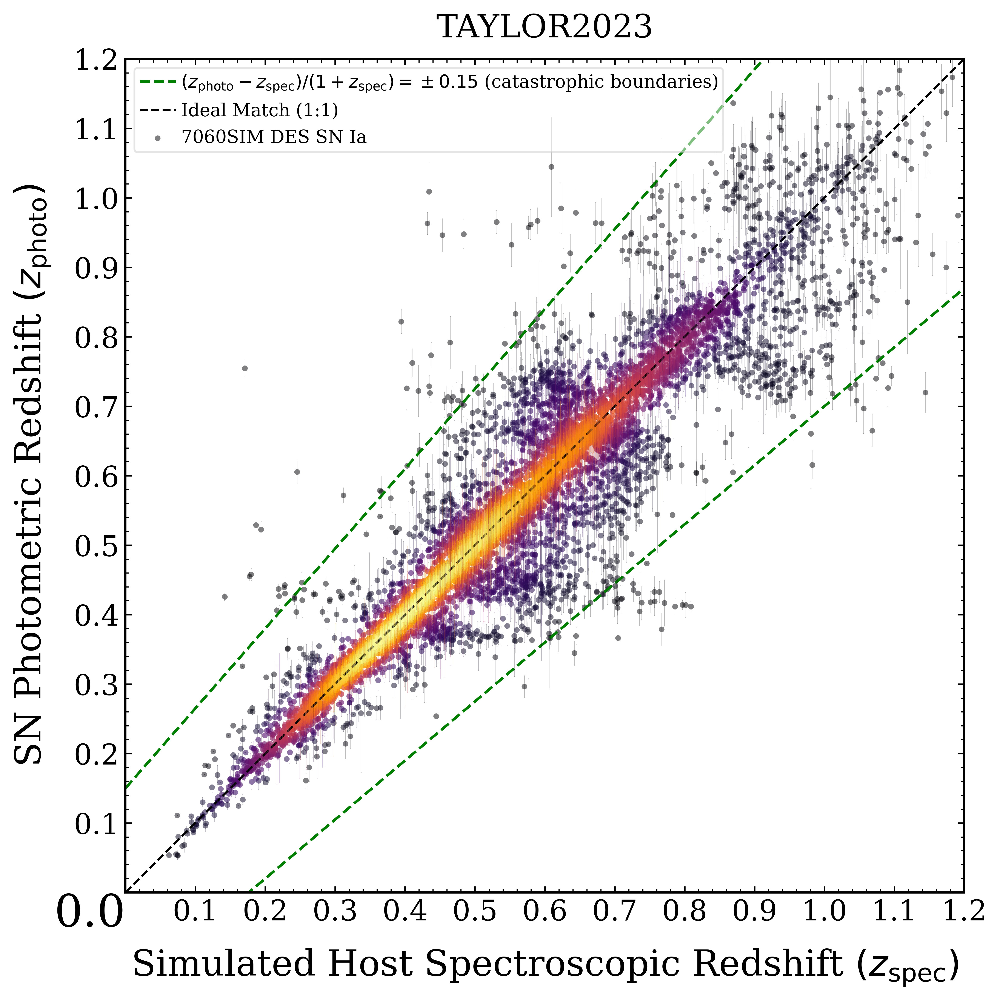

In [42]:
# plot_photoz_density_mnras(trial_taylor['REDSHIFT_FINAL'], trial_taylor['photoz_sncosmo'], trial_taylor['photoz_err_sncosmo'] , 'TAYLOR2023', 'SIM DES SN Ia ', 8, 8)




In [57]:
# trial_dov = pd.merge(total, df_dov, how = 'left', on = 'SNID')
# trial_dov = trial_dov[trial_dov['photoz_sncosmo'] >0]
# trial_dov = pd.merge(snana_dov, trial_dov, how = 'left', left_on = 'CID', right_on = 'SNID') 
# trial_dov 

,VARNAMES:,CID,CIDint,IDSURVEY,TYPE,FIELD,CUTFLAG_SNANA,ERRFLAG_FIT,RA_x,DEC_x,zHEL,zHELERR,zCMB,zCMBERR,zHD,zHDERR,VPEC_x,VPECERR,LENSDMU_x,LENSDMUERR,MWEBV_x,HOST_NMATCH,HOST_NMATCH2,HOST_OBJID,HOST_ZPHOT,HOST_ZPHOTERR,HOST_ZSPEC,HOST_ZSPECERR,HOST_RA,HOST_DEC,HOST_ANGSEP,HOST_DDLR,HOST_CONFUSION,HOST_LOGMASS,HOST_LOGMASS_ERR,HOST_LOGSFR,HOST_LOGSFR_ERR,HOST_LOGsSFR,HOST_LOGsSFR_ERR,HOST_COLOR,HOST_COLOR_ERR,HOST_MAG_g,HOST_MAG_r,HOST_MAG_i,HOST_MAG_z,HOST_MAGERR_g,HOST_MAGERR_r,HOST_MAGERR_i,HOST_MAGERR_z,HOST_SBFLUXCAL_g,HOST_SBFLUXCAL_r,HOST_SBFLUXCAL_i,HOST_SBFLUXCAL_z,HOST_SBMAG_g,HOST_SBMAG_r,HOST_SBMAG_i,HOST_SBMAG_z,PKMJDINI,SNRMAX1,SNRMAX2,SNRMAX3,SNRSUM,BANDLIST,PKMJD,PKMJDERR,x1,x1ERR,c,cERR,mB,mBERR,x0,x0ERR,COV_x1_c,COV_x1_x0,COV_c_x0,NDOF,FITCHI2,FITPROB,RADIUS_POP,SIM_GENTYPE_x,SIM_TEMPLATE_INDEX_x,SIM_LIBID_x,SIM_NGEN_LIBID_x,SIM_ZCMB,SIM_ZHOST_MATCH,SIM_ZFLAG,SIM_VPEC_x,SIM_DLMAG,SIM_LENSDMU_x,SIM_PEAKMJD_x,SIM_WGT_POP,SIM_x1,SIM_c,SIM_alpha,SIM_beta,SIM_gammaDM,SIM_x0,SIM_mB,SIM_AV_x,SIM_RV_x,SIM_HOSTLIB_GALID_x,SIM_HOSTLIB_r_obs_auto,SIM_HOSTLIB_obs_gr_auto,SIM_HOSTLIB_LOGMASS_TRUE,SIM_HOSTLIB_ZTRUE,RA_2,DEC_2,HOST_ANGSEP_2,TGAPMAX,TrestMIN,TrestMAX,FLUXCALMAX_g,SNRMAX_g,FLUXCALMAX_r,SNRMAX_r,FLUXCALMAX_i,SNRMAX_i,FLUXCALMAX_z,SNRMAX_z,m0obs_r,m0obs_i,m0obs_g,PROB_model1,SNID,FAKE,RA_y,DEC_y,PIXSIZE,NXPIX,NYPIX,SNTYPE,NOBS,PTROBS_MIN,PTROBS_MAX,MWEBV_y,MWEBV_ERR,REDSHIFT_HELIO,REDSHIFT_HELIO_ERR,REDSHIFT_FINAL,REDSHIFT_FINAL_ERR,MASK_REDSHIFT_SOURCE,VPEC_y,VPEC_ERR,LENSDMU_y,LENSDMU_ERR,HOSTGAL_NMATCH,HOSTGAL_NMATCH2,HOSTGAL_OBJID,HOSTGAL_FLAG,HOSTGAL_PHOTOZ,HOSTGAL_PHOTOZ_ERR,HOSTGAL_SPECZ,HOSTGAL_SPECZ_ERR,HOSTGAL_RA,HOSTGAL_DEC,HOSTGAL_SNSEP,HOSTGAL_DDLR,HOSTGAL_CONFUSION,HOSTGAL_LOGMASS,HOSTGAL_LOGMASS_ERR,HOSTGAL_LOGSFR,HOSTGAL_LOGSFR_ERR,HOSTGAL_LOGsSFR,HOSTGAL_LOGsSFR_ERR,HOSTGAL_COLOR,HOSTGAL_COLOR_ERR,HOSTGAL_ELLIPTICITY,HOSTGAL_OBJID2,HOSTGAL_SQRADIUS,HOSTGAL_OBJID_UNIQUE,HOSTGAL_MAG_g,HOSTGAL_MAG_r,HOSTGAL_MAG_i,HOSTGAL_MAG_z,HOSTGAL_MAGERR_g,HOSTGAL_MAGERR_r,HOSTGAL_MAGERR_i,HOSTGAL_MAGERR_z,HOSTGAL2_OBJID,HOSTGAL2_FLAG,HOSTGAL2_PHOTOZ,HOSTGAL2_PHOTOZ_ERR,HOSTGAL2_SPECZ,HOSTGAL2_SPECZ_ERR,HOSTGAL2_RA,HOSTGAL2_DEC,HOSTGAL2_SNSEP,HOSTGAL2_DDLR,HOSTGAL2_LOGMASS,HOSTGAL2_LOGMASS_ERR,HOSTGAL2_LOGSFR,HOSTGAL2_LOGSFR_ERR,HOSTGAL2_LOGsSFR,HOSTGAL2_LOGsSFR_ERR,HOSTGAL2_COLOR,HOSTGAL2_COLOR_ERR,HOSTGAL2_ELLIPTICITY,HOSTGAL2_OBJID2,HOSTGAL2_SQRADIUS,HOSTGAL2_OBJID_UNIQUE,HOSTGAL2_MAG_g,HOSTGAL2_MAG_r,HOSTGAL2_MAG_i,HOSTGAL2_MAG_z,HOSTGAL2_MAGERR_g,HOSTGAL2_MAGERR_r,HOSTGAL2_MAGERR_i,HOSTGAL2_MAGERR_z,HOSTGAL_SB_FLUXCAL_g,HOSTGAL_SB_FLUXCAL_r,HOSTGAL_SB_FLUXCAL_i,HOSTGAL_SB_FLUXCAL_z,PEAKMJD,MJD_TRIGGER,MJD_DETECT_FIRST,MJD_DETECT_LAST,SEARCH_TYPE,SIM_MODEL_NAME,SIM_MODEL_INDEX,SIM_GENTYPE_y,SIM_TYPE_INDEX,SIM_TYPE_NAME,SIM_TEMPLATE_INDEX_y,SIM_LIBID_y,SIM_NGEN_LIBID_y,SIM_NOBS_UNDEFINED,SIM_SEARCHEFF_MASK,SIM_REDSHIFT_HELIO,SIM_REDSHIFT_CMB,SIM_REDSHIFT_HOST,SIM_REDSHIFT_HOST_MATCH,SIM_REDSHIFT_FLAG,SIM_VPEC_y,SIM_HOSTLIB_GALID_y,SIM_HOSTLIB(r_obs_auto),SIM_HOSTLIB(obs_gr_auto),SIM_HOSTLIB(LOGMASS_TRUE),SIM_HOSTLIB(ZTRUE),SIM_SNHOST_DDLR,SIM_SNHOST_SEP,SIM_DLMU,SIM_LENSDMU_y,SIM_MUSHIFT,SIM_RA,SIM_DEC,SIM_MWEBV,SIM_PEAKMJD_y,SIM_MJD_EXPLODE,SIM_MAGSMEAR_COH,SIM_WGT_POPULATION,SIM_AV_y,SIM_RV_y,SIM_SALT2x0,SIM_SALT2x1,SIM_SALT2c,SIM_SALT2mB,SIM_SALT2alpha,SIM_SALT2beta,SIM_SALT2gammaDM,SIM_PEAKMAG_g,SIM_PEAKMAG_r,SIM_PEAKMAG_i,SIM_PEAKMAG_z,SIM_EXPOSURE_g,SIM_EXPOSURE_r,SIM_EXPOSURE_i,SIM_EXPOSURE_z,SIM_GALFRAC_g,SIM_GALFRAC_r,SIM_GALFRAC_i,SIM_GALFRAC_z,SIM_SUBSAMPLE_INDEX,photoz_sncosmo,photoz_err_sncosmo
0,SN:,148145,148145,10,1,E1,3,0,8.236995,-42.561256,0.49451,0.01357,0.49451,0.01357,0.49451,0.01366,0,300,0.000578,0,0.008452,1,1,2200331016,-9,-9,0.49451,1.357490e-02,8.236731,-42.561394,0.857230,1.461910,-9.000000,8.273,-9999,-0.077,-9999,-9999,-9999,-0.052,-9999,24.66224,24.03825,23.86315,23.75834,-9,-9,-9,-9,2.86980,5.09856,5.99080,6.59797,26.35537,25.73138,25.55629,25.45147,57985.2148,27.17096,19.7

In [58]:
# photometric_values(trial_dov)

112 catastrophic outliers
catastrophic outliers percentage:  1.580358402709186 %

bias:  0.0020285511597484263

simga_nmad:  0.024211098951785654
Dz_norm std:  0.14223608503827306


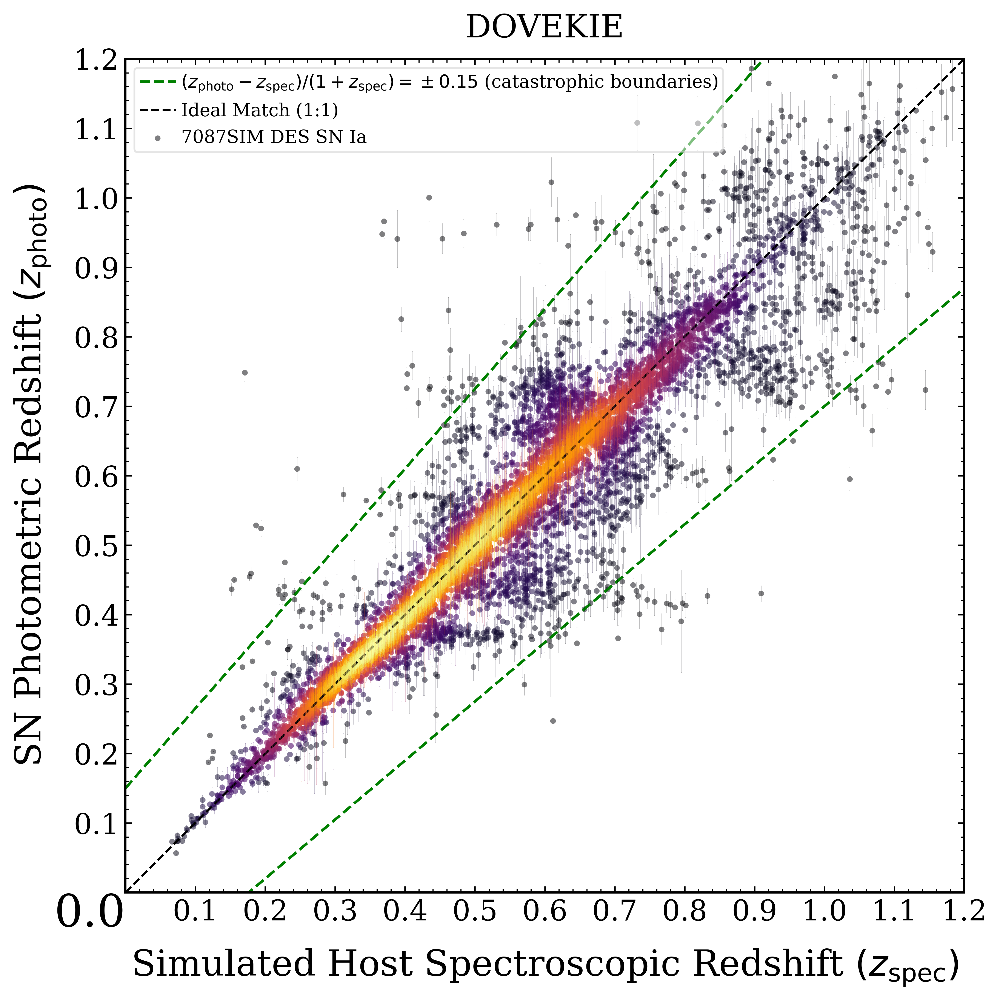

In [43]:
# plot_photoz_density_mnras(trial_dov['REDSHIFT_FINAL'], trial_dov['photoz_sncosmo'], trial_dov['photoz_err_sncosmo'] , 'DOVEKIE', 'SIM DES SN Ia ', 8, 8)

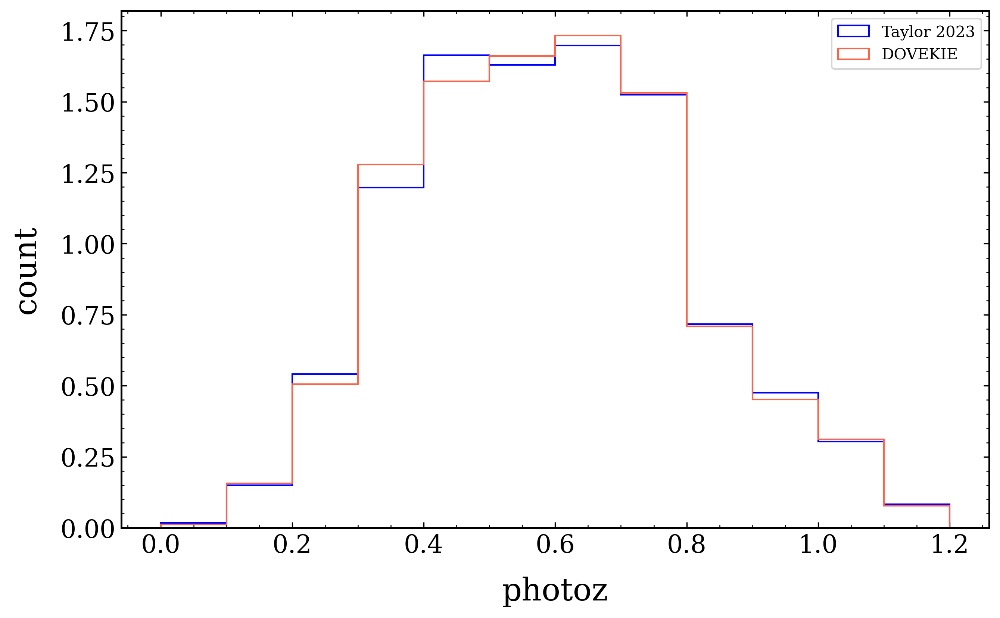

In [35]:
# plt.figure(figsize = (10,6), dpi=300)
# plt.hist(trial_taylor['photoz_sncosmo'], bins = np.arange(0.0,1.3, 0.1), density = True, color = 'blue', histtype='step', label = 'Taylor 2023')
# plt.hist(trial_dov['photoz_sncosmo'], bins = np.arange(0.0,1.3, 0.1), density = True, color = 'tomato',  histtype='step', label = 'DOVEKIE')
# plt.xlabel('photoz')
# plt.ylabel('count')
# plt.legend()
# plt.show()

In [303]:
# ns26 = pd.read_csv('/media/data1/nikolaos/des_projects/DES_5YRSN_LC/DES_5YRSN_LC_shiamrock_0_19706_ALL.csv', sep = ' ')

# bp = pd.read_csv('/media/data1/nikolaos/des_projects/DES_5YRSN_LC/FITOPT000_BP25_DOV.FITRES.gz', sep=r'\s+', compression='gzip', comment='#')
# bp = bp[bp['IDSURVEY'] ==10]
# bp['CID'] = bp['CID'].astype(int)

In [304]:
# test = pd.merge(ns26, bp , how = 'left', left_on = 'SNID', right_on = 'CID')
# test = test[test['zHEL'] >0]
# test

,SNID,photoz_sncosmo,photoz_err_sncosmo,t0_photoz_sncosmo,t0_err_photoz_sncosmo,x0_photoz_sncosmo,x0_err_photoz_sncosmo,x1_photoz_sncosmo,x1_err_photoz_sncosmo,c_photoz_sncosmo,c_err_photoz_sncosmo,chisqr_sncosmo,dof_sncosmo,VARNAMES:,CID,CIDint,IDSURVEY,TYPE,FIELD,CUTFLAG_SNANA,ERRFLAG_FIT,zHEL,zHELERR,zCMB,zCMBERR,zHD,zHDERR,VPEC,VPECERR,LENSDMU,LENSDMUERR,MWEBV,HOST_NMATCH,HOST_NMATCH2,HOST_OBJID,HOST_ZPHOT,HOST_ZPHOTERR,HOST_ZSPEC,HOST_ZSPECERR,HOST_RA,HOST_DEC,HOST_ANGSEP,HOST_DDLR,HOST_CONFUSION,HOST_LOGMASS,HOST_LOGMASS_ERR,HOST_LOGSFR,HOST_LOGSFR_ERR,HOST_LOGsSFR,HOST_LOGsSFR_ERR,HOST_COLOR,HOST_COLOR_ERR,HOST_MAG_g,HOST_MAG_i,HOST_SBFLUXCAL_g,HOST_SBFLUXCAL_i,HOST_SBMAG_g,HOST_SBMAG_i,PKMJDINI,SNRMAX1,SNRMAX2,SNRMAX3,SNRSUM,BANDLIST,PKMJD,PKMJDERR,x1,x1ERR,c,cERR,mB,mBERR,x0,x0ERR,COV_x1_c,COV_x1_x0,COV_c_x0,NDOF,FITCHI2,FITPROB,RADIUS_POP,PROB_SCONE,PROB_SNIRFV19,PROB_SNNDESCC,PROB_SNNJ17,PROB_SNNV19,CUTMASK,MU,MUMODEL,MUERR,MUERR_RENORM,MUERR_RAW,MUERR_VPEC,MURES,MUPULL,M0DIF,M0DIFERR,CHI2_BEAMS,PROBCC_BEAMS,biasCor_nevt,biasCor_mu,biasCorErr_mu,biasCor_muCOVSCALE,biasCor_muCOVADD,IDSAMPLE,IZBIN
1,1257356,0.339842,0.007381,56616.423702,0.163973,0.000027,6.639974e-07,-0.554479,0.201841,-0.010832,2.269010e-02,178.726350,83,SN:,1257356.0,1257356.0,10.0,0.0,C1,3.0,0.0,0.33307,0.001,0.33257,0.001,0.33257,0.00167,0.0,300.0,0.0,0.0,0.009559,1.0,3.0,1545.0,-9.0,-9.0,0.3331,0.001,54.377510,-26.515162,0.520,0.647,-3.32223,10.169,0.023,0.161,7.201,-10.035,7.201540,1.433,-999.0,22.97,20.96,13.20,85.73,24.69856,22.66717,56614.0742,32.96088,24.66165,21.47324,80.98146,griz,56616.3711,0.2507,-0.799226,0.300350,-0.030347,0.028454,21.71675,0.039110,0.000037,1.330040e-06,0.005011,-2.978000e-07,-2.973100e-08,45.0,34.37711,0.875050,0.284967,0.9998,0.9783,1.0000,0.9999,1.0000,0.0,41.07062,41.20908,0.11991,0.1195,0.0676,0.0075,-0.1410,-1.176,0.0025,0.0125,0.93,0.000000,17034.0,-0.0496,0.002,1.000,0.0085,6.0,10.0
2,1259330,0.581824,0.026849,56612.650665,0.897839,0.000005,3.950002e-07,-0.272702,0.878686,0.165988,8.120056e-02,113.503712,72,SN:,1259330.0,1259330.0,10.0,0.0,E2,3.0,0.0,0.60357,0.001,0.60243,0.001,0.60243,0.00189,0.0,300.0,0.0,0.0,0.005263,1.0,1.0,9380.0,-9.0,-9.0,0.6036,0.001,10.287661,-44.204525,0.403,0.269,-9.00000,10.772,0.010,0.888,0.047,-9.886,0.072346,1.320,-999.0,24.02,21.96,4.83,34.15,25.79013,23.66652,56615.0742,7.07045,6.54569,6.06610,21.49703,riz,56613.1250,1.0171,0.055722,1.024770,0.201280,0.094526,23.67348,0.100970,0.000006,5.663180e-07,0.032266,-4.090710e-07,-3.605090e-08,34.0,39.06209,0.252770,0.671193,0.9883,0.9568,0.9991,0.9973,0.9933,0.0,42.86699,42.73337,0.20561,0.2111,0.2819,0.0044,0.1274,0.620,0.0062,0.0107,1.02,0.000761,4930.0,-0.4733,0.007,0.524,0.0000,6.0,15.0
4,1256680,0.320410,0.009949,56599.590461,0.361092,0.000022,3.848068e-07,0.025148,0.258381,0.021062,2.481597e-02,242.125186,92,SN:,1256680.0,1256680.0,10.0,0.0,X1,3.0,0.0,0.29546,0.001,0.29438,0.001,0.29438,0.00164,0.0,300.0,0.0,0.0,0.019639,1.0,1.0,14370.0,-9.0,-9.0,0.2955,0.001,33.899609,-5.664846,0.349,0.229,-9.00000,9.705,0.039,1.482,0.305,-8.202,0.335180,0.114,-999.0,22.07,21.12,39.05,91.89,23.52095,22.59183,56602.0664,37.18655,34.07638,29.36660,75.83642,griz,56599.2656,0.3771,-0.451661,0.353210,0.039875,0.024601,21.94000,0.028580,0.000030,7.912890e-07,0.003784,-1.483350e-07,-1.285540e-08,35.0,51.37879,0.036518,0.200831,0.9925,0.9427,0.9998,0.9995,0.9999,0.0,41.07496,40.90485,0.18627,0.1846,0.0741,0.0083,0.1837,0.986,-0.0136,0.0162,1.41,0.000006,2591.0,-0.0260,0.008,1.000,0.0279,4.0,9.0
7,1263369,0.341113,0.008818,56666.136052,0.184187,0.000032,3.944003e-07,0.345151,0.198068,-0.072943,1.867290e-02,94.039205,53,SN:,1263369.0,1263369.0,10.0,1.0,S1,3.0,0.0,0.31343,0.001,0.31251,0.001,0.31251,0.00165,0.0,300.0,0.0,0.0,0.056573,1.0,1.0,11119.0,-9.0,-9.0,0.3134,0.001,43.229355,-0.541303,1.962,1.167,-9.00000,10.478,0.011,1.055,0.241,-9.380,0.241830,0.963,-999.0,22.63,20.90,15.86,71.19,24.49924,22.86895,56669.0469,50.80721,47.01299,25.21381,103.77638,g

In [305]:
# NS = pd.read_hdf('Master_file_cosmology_SNANA.h5', key = 'table')
# NS = NS[ (NS['photoz'] > 0) & (NS['x0_SNANA'] > 0)]
# hq_NS = NS[ ((np.abs(NS['x1_SNANA']) < 3) & (np.abs(NS['c_SNANA']) < 0.3) & 
#             (NS['x1_err_SNANA'] < 1.15)  & (NS['t0_err_SNANA'] < 2)  &  (NS['c_err_SNANA'] < 0.2)   & (NS['probfit_salt3_SNANA'] > 0.001) )]

# hq_NS= hq_NS[hq_NS['specz_des']>0]
# hq_NS = hq_NS[['SNID', 'x0_SNANA']]

# test = pd.merge(test, hq_NS, how = 'left', on = 'SNID')
# test = test[test['x0_SNANA'] > 0]
# test

In [306]:
# photometric_values(test)


23 catastrophic outliers
catastrophic outliers percentage:  1.6522988505747127 %

bias:  -0.0006473996899059031

simga_nmad:  0.02183862001579845
Dz_norm std:  0.1209145410514596


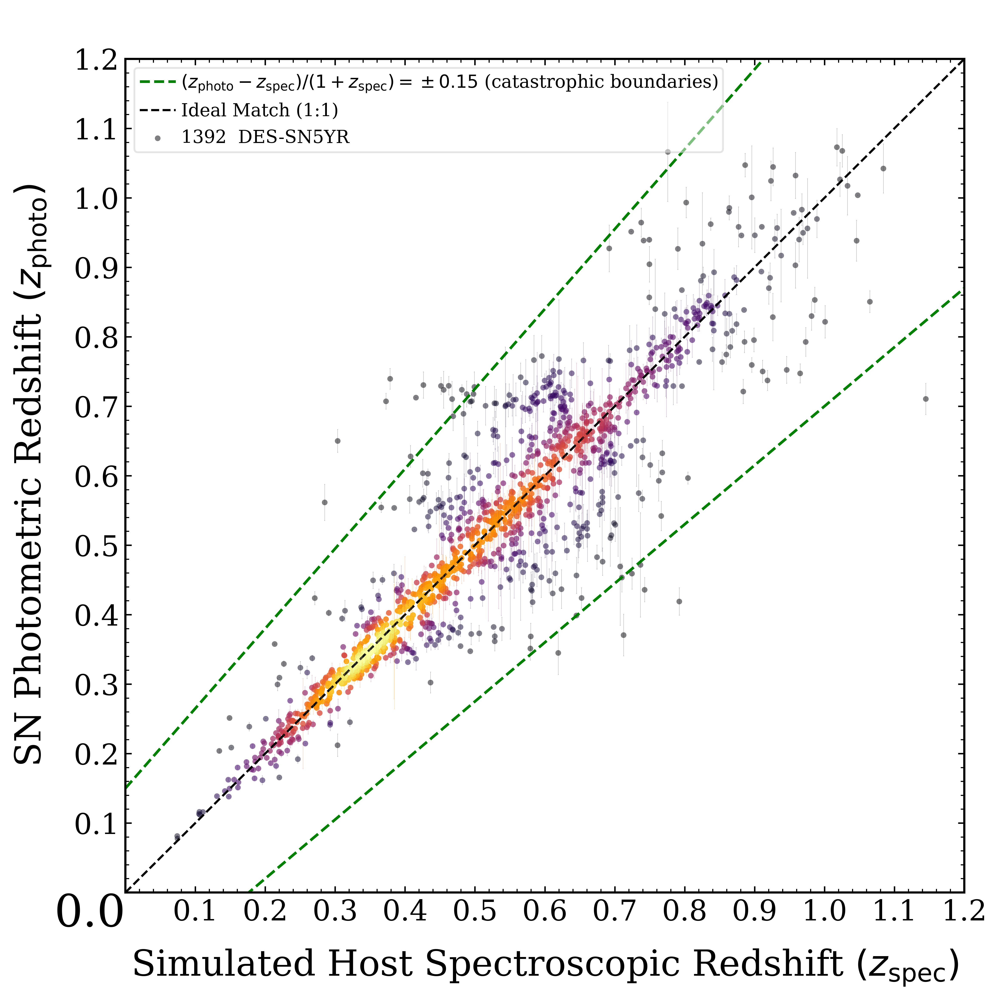

In [307]:
# plot_photoz_density_mnras(test['zHEL'], test['photoz_sncosmo'], test['photoz_err_sncosmo'] ,' ', '  DES-SN5YR ', 8, 8)




In [13]:
# trial = pd.read_csv('/media/data1/nikolaos/des_projects/PIP_NS26_BBC_SIMS_SIMS_BBC/PIP_NS26_BBC_SIMS_SIMS_BBC_shiamrock_0_387305_ALL.csv', sep=' ')
# # total['SNID'] = total['SNID'].astype(int)
# # trial = pd.merge(trial, total[['SNID', 'REDSHIFT_FINAL']], how = 'left', on = 'SNID')


In [28]:
# trial2 = pd.read_csv('/media/data1/nikolaos/des_projects/PIP_NS26_BBC_SIMS_SIMS_BBC/PIP_NS26_BBC_SIMS_SIMS_BBC_shiamrock_HEADER_OVERRIDE.dat', sep = ' ')

# trial2[trial2['SNID']== 3073697]

,VARNAMES:,SNID,REDSHIFT_HELIO,HOSTGAL_SPECZ,REDSHIFT_FINAL,REDSHIFT_HELIO_ERR,HOSTGAL_SPECZ_ERR,REDSHIFT_FINAL_ERR
379244,SN:,3073697,0.03942,0.03942,0.03942,0.000025,0.000025,0.000025


In [29]:
# total[total['SNID']=='3073697']

,SNID,FAKE,RA,DEC,PIXSIZE,NXPIX,NYPIX,SNTYPE,NOBS,PTROBS_MIN,PTROBS_MAX,MWEBV,MWEBV_ERR,REDSHIFT_HELIO,REDSHIFT_HELIO_ERR,REDSHIFT_FINAL,REDSHIFT_FINAL_ERR,MASK_REDSHIFT_SOURCE,VPEC,VPEC_ERR,LENSDMU,LENSDMU_ERR,HOSTGAL_NMATCH,HOSTGAL_NMATCH2,HOSTGAL_OBJID,HOSTGAL_FLAG,HOSTGAL_PHOTOZ,HOSTGAL_PHOTOZ_ERR,HOSTGAL_SPECZ,HOSTGAL_SPECZ_ERR,HOSTGAL_RA,HOSTGAL_DEC,HOSTGAL_SNSEP,HOSTGAL_DDLR,HOSTGAL_CONFUSION,HOSTGAL_LOGMASS,HOSTGAL_LOGMASS_ERR,HOSTGAL_LOGSFR,HOSTGAL_LOGSFR_ERR,HOSTGAL_LOGsSFR,HOSTGAL_LOGsSFR_ERR,HOSTGAL_COLOR,HOSTGAL_COLOR_ERR,HOSTGAL_ELLIPTICITY,HOSTGAL_OBJID2,HOSTGAL_SQRADIUS,HOSTGAL_OBJID_UNIQUE,HOSTGAL_MAG_g,HOSTGAL_MAG_r,HOSTGAL_MAG_i,HOSTGAL_MAG_z,HOSTGAL_MAGERR_g,HOSTGAL_MAGERR_r,HOSTGAL_MAGERR_i,HOSTGAL_MAGERR_z,HOSTGAL2_OBJID,HOSTGAL2_FLAG,HOSTGAL2_PHOTOZ,HOSTGAL2_PHOTOZ_ERR,HOSTGAL2_SPECZ,HOSTGAL2_SPECZ_ERR,HOSTGAL2_RA,HOSTGAL2_DEC,HOSTGAL2_SNSEP,HOSTGAL2_DDLR,HOSTGAL2_LOGMASS,HOSTGAL2_LOGMASS_ERR,HOSTGAL2_LOGSFR,HOSTGAL2_LOGSFR_ERR,HOSTGAL2_LOGsSFR,HOSTGAL2_LOGsSFR_ERR,HOSTGAL2_COLOR,HOSTGAL2_COLOR_ERR,HOSTGAL2_ELLIPTICITY,HOSTGAL2_OBJID2,HOSTGAL2_SQRADIUS,HOSTGAL2_OBJID_UNIQUE,HOSTGAL2_MAG_g,HOSTGAL2_MAG_r,HOSTGAL2_MAG_i,HOSTGAL2_MAG_z,HOSTGAL2_MAGERR_g,HOSTGAL2_MAGERR_r,HOSTGAL2_MAGERR_i,HOSTGAL2_MAGERR_z,HOSTGAL_SB_FLUXCAL_g,HOSTGAL_SB_FLUXCAL_r,HOSTGAL_SB_FLUXCAL_i,HOSTGAL_SB_FLUXCAL_z,PEAKMJD,MJD_TRIGGER,MJD_DETECT_FIRST,MJD_DETECT_LAST,SEARCH_TYPE,SIM_MODEL_NAME,SIM_MODEL_INDEX,SIM_GENTYPE,SIM_TYPE_INDEX,SIM_TYPE_NAME,SIM_TEMPLATE_INDEX,SIM_LIBID,SIM_NGEN_LIBID,SIM_NOBS_UNDEFINED,SIM_SEARCHEFF_MASK,SIM_REDSHIFT_HELIO,SIM_REDSHIFT_CMB,SIM_REDSHIFT_HOST,SIM_REDSHIFT_HOST_MATCH,SIM_REDSHIFT_FLAG,SIM_VPEC,SIM_HOSTLIB_GALID,SIM_HOSTLIB(r_obs_auto),SIM_HOSTLIB(obs_gr_auto),SIM_HOSTLIB(LOGMASS_TRUE),SIM_HOSTLIB(ZTRUE),SIM_SNHOST_DDLR,SIM_SNHOST_SEP,SIM_DLMU,SIM_LENSDMU,SIM_MUSHIFT,SIM_RA,SIM_DEC,SIM_MWEBV,SIM_PEAKMJD,SIM_MJD_EXPLODE,SIM_MAGSMEAR_COH,SIM_WGT_POPULATION,SIM_AV,SIM_RV,SIM_SALT2x0,SIM_SALT2x1,SIM_SALT2c,SIM_SALT2mB,SIM_SALT2alpha,SIM_SALT2beta,SIM_SALT2gammaDM,SIM_PEAKMAG_g,SIM_PEAKMAG_r,SIM_PEAKMAG_i,SIM_PEAKMAG_z,SIM_EXPOSURE_g,SIM_EXPOSURE_r,SIM_EXPOSURE_i,SIM_EXPOSURE_z,SIM_GALFRAC_g,SIM_GALFRAC_r,SIM_GALFRAC_i,SIM_GALFRAC_z,SIM_SUBSAMPLE_INDEX
379244,3073697,2,36.360645,-4.173872,0.27,-9,-9,1,19,659459,659477,0.023855,0.001193,0.060933,0.00001,0.060085,0.00001,2,0.0,300.0,0.000332,0.0,1,1,2200381793,0,-9.0,-9.0,0.060933,0.00001,36.360415,-4.173795,0.872308,1.135686,-99.0,11.481,-9999.0,0.502,-9999.0,-9999.0,-9999.0,1.244,-9999.0,999.0,-9,999.0,-9,23.605995,22.094025,21.340752,19.840769,-9.0,-9.0,-9.0,-9.0,0,0,-9.0,-9.0,-9.0,-9.0,-999.0,-999.0,-9.0,-9.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,-9999.0,0,-9999.0,0,999.0,999.0,999.0,999.0,999.0,999.0,999.0,999.0,5.200658,20.933727,41.894375,166.781784,57038.117188,57036.039062,57032.0625,57049.054688,-9,SALT3.DOVEKIE,6,1,1,SALT3.DOVEKI,0,4682,1,0,11,0.060936,0.059592,0.06007,0.06007,1,140.382446,2200381793,22.28937,1.422694,11.481,0.06007,1.135686,0.872308,37.132904,0.000332,0.0,36.360645,-4.173872,0.022116,57044.566406,-9.0,-0.035428,1.0,0.477427,1.40027,0.001678,-0.528443,-0.125558,17.572876,0.15,2.184613,0.0,18.42288,18.204782,18.683126,-9.0,1.0,1.0,1.0,1.0,0.003335,0.010982,0.034144,1.148292e-12,-9


In [31]:
# photometric_values(trial)


25171 catastrophic outliers
catastrophic outliers percentage:  7.250756157280715 %

bias:  0.003336968790234096

simga_nmad:  0.040535532338815856
Dz_norm std:  0.17561310945622027


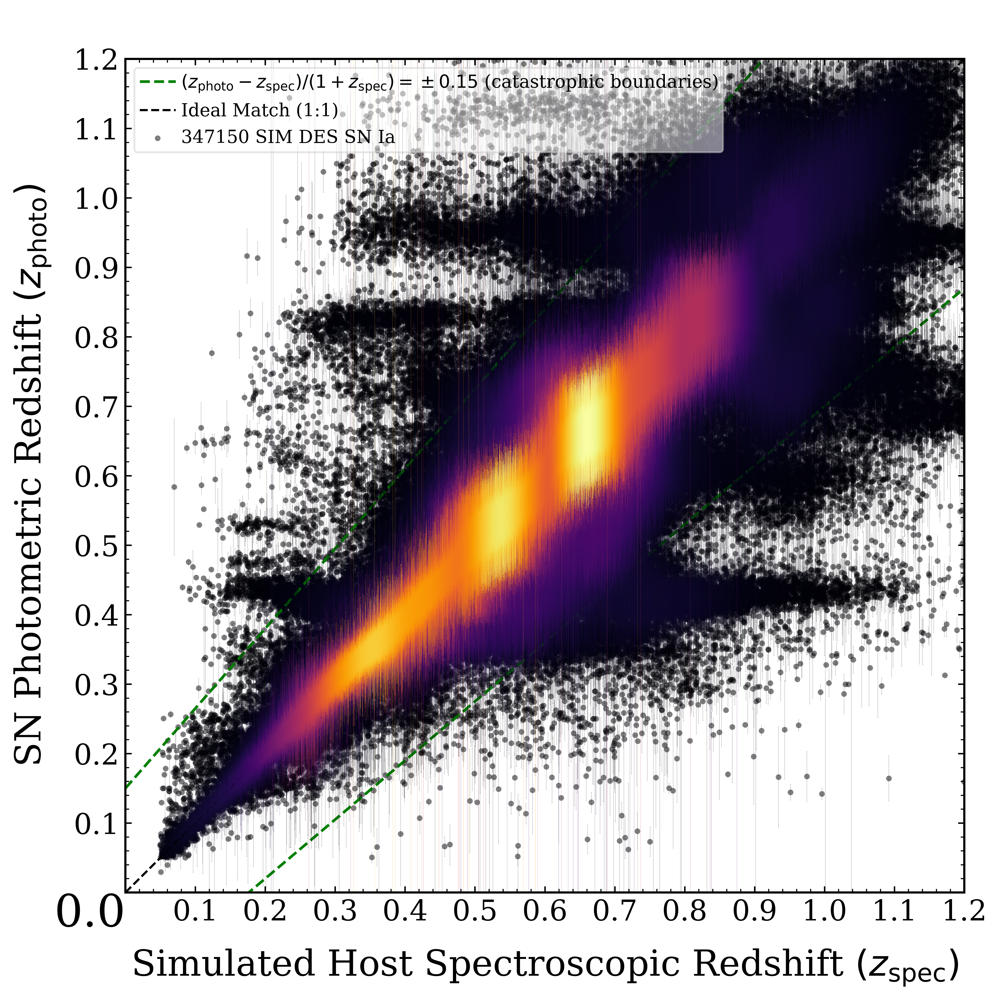

In [32]:
# plot_photoz_density_mnras(trial['REDSHIFT_FINAL'], trial['photoz_sncosmo'], trial['photoz_err_sncosmo'] , ' ', ' SIM DES SN Ia ', 8, 8)


